In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load cleaned Netflix dataset

df = pd.read_csv("netflix_cleaned_dataset.csv")

# Display first 5 rows
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [5]:
# Display country column
df["country"].head(10)

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: object

In [6]:
# Check missing country values
print("Missing country values:", df["country"].isnull().sum())

Missing country values: 0


In [7]:
print(df["country"].dtype)

object


In [10]:
# check for missing values in country .
print("missing values of country: ",df["country"].isna().sum())

missing values of country:  0


In [11]:
print("unique country enteries:", df["country"].nunique())

unique country enteries: 86


In [12]:
country_data = (df["country"].str.split(",").explode().str.strip())

print("Indivdual country values:")
print(country_data.head(20))

Indivdual country values:
0      United States
1             France
2      United States
3             Brazil
4      United States
5     United Kingdom
6      United States
7              India
8            Germany
9              India
10             India
11             India
12          Pakistan
13     United States
14     United States
15     United States
16     United States
17          Pakistan
18          Pakistan
19     United States
Name: country, dtype: object


In [14]:
# count how many titles are associated with each others country.

country_counts = country_data.value_counts()
print("top 20 countries by content count:")
print(country_counts.head(20))

top 20 countries by content count:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             112
Nigeria            105
Germany            104
China              100
Brazil              88
Taiwan              86
Indonesia           86
Name: count, dtype: int64


In [30]:
 country_df = country_counts.reset_index()

country_df.columns = ["country","content_count"]

print("country - wise content count:")
print(country_df.head(20))

country - wise content count:
           country  content_count
0    United States           3240
1            India           1057
2   United Kingdom            638
3         Pakistan            421
4        Not Given            287
5           Canada            271
6            Japan            259
7      South Korea            214
8           France            213
9            Spain            182
10          Mexico            138
11           Egypt            123
12       Australia            114
13          Turkey            112
14         Nigeria            105
15         Germany            104
16           China            100
17          Brazil             88
18          Taiwan             86
19       Indonesia             86


In [16]:
# check total no. of countries 

print("total numbers of countries:", len(country_df))

total numbers of countries: 86


In [34]:
# remove "not given " from the country analysis.
country_analysis = country_df[country_df["country"] != "Not Given"].copy()

In [57]:
country_analysis = country_analysis.sort_values(by="content_count", ascending=False)

In [22]:
top_10_countries = country_analysis.head(10).copy()

In [36]:
top_10_countries["Rank"] = range(1,11)

In [65]:
# display the final top 10 ranking 
total_content = country_analysis["content_count"].sum()


In [28]:
# visualize top 10 countries 

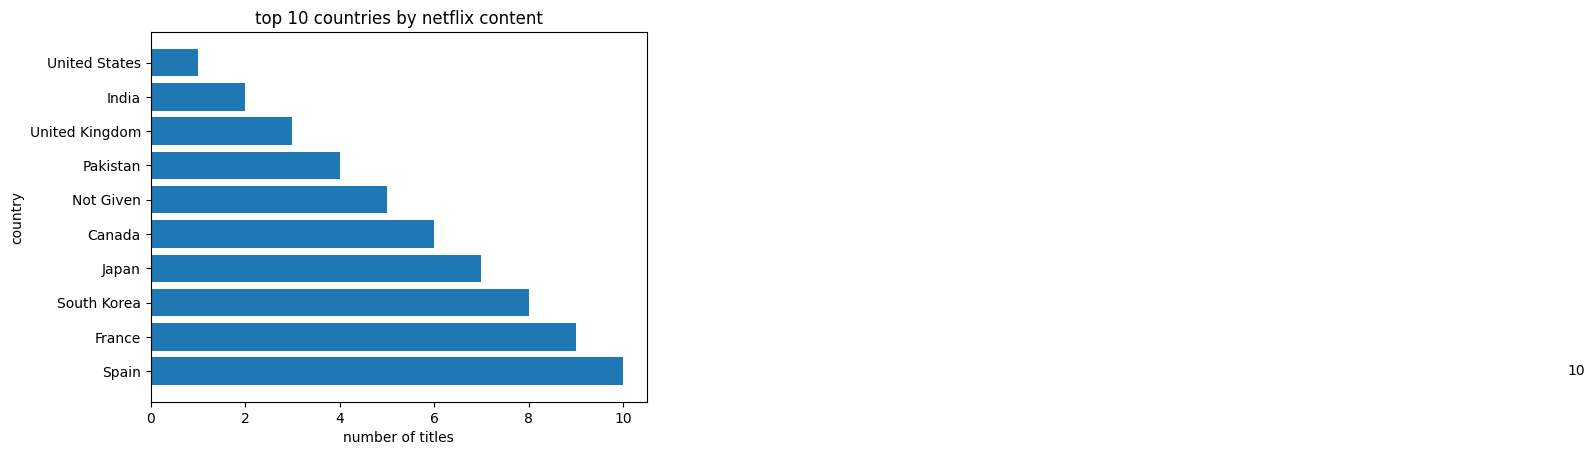

In [75]:
import matplotlib.pyplot as plt 

# plt.figure(figsize=(100,70))

bars = plt.barh(top_10_countries["country"],top_10_countries["Rank"])
plt.title("top 10 countries by netflix content")

plt.xlabel("number of titles")
plt.ylabel("country")

plt.gca().invert_yaxis()

for bar in bars:
    value = bar.get_width()

plt.text(value +20, bar.get_y() + bar.get_height()/2, str(int(value)), va="center")

# plt.tight_layout()

plt.show()